# Punto 1.5 — Implementación en Qiskit

En este notebook se implementan los puntos 1.3 y 1.4 para un estado $|\psi\rangle=\alpha|0\rangle+\beta|1\rangle$ cualquiera:

* **(a)** la construcción de $|\psi'\rangle$ y $\eta$ del punto 1.3,
* **(b)** el estado mixto $p\rho+(1-p)\rho'$ del punto 1.4 para varios valores de $p$,
* **(c)** los vectores de Bloch de todos los estados, para compararlos con los del widget del punto 1.2.

En (a) y (b) se reportan las probabilidades exactas y las frecuencias de mediciones simuladas.
Se usan las herramientas del curso de IBM Quantum Learning (*Basics of quantum information*): `Statevector`, `DensityMatrix`, circuitos con `QuantumCircuit` y el `StatevectorSampler` para simular las mediciones.

In [1]:
# Si hace falta instalar:
# %pip install qiskit matplotlib pandas pylatexenc sympy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, DensityMatrix
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_bloch_vector, plot_histogram
from qiskit.visualization.bloch import Bloch

rng = np.random.default_rng(2026)   # semilla para que los resultados se puedan repetir
SHOTS = 4000                        # número de mediciones simuladas
sampler = StatevectorSampler(seed=rng)   # usa el mismo generador, así cada corrida da muestras distintas

## El estado $|\psi\rangle$

Se usa el mismo estado del ejemplo de los puntos 1.3 y 1.4,
$$|\psi\rangle=\tfrac{\sqrt3}{2}|0\rangle+\tfrac{i}{2}|1\rangle ,$$
pero todas las funciones reciben $\alpha$ y $\beta$ cualesquiera, así que al final se prueban también con estados al azar.

In [2]:
alpha = np.sqrt(3) / 2
beta = 1j / 2

psi = Statevector([alpha, beta])
print("norma:", psi.inner(psi).real)   # <psi|psi> debe dar 1
psi.draw("latex")

norma: 0.9999999999999999


<IPython.core.display.Latex object>

## (a) Construcción de $|\psi'\rangle$ y $\eta$

En el punto 1.3 se encontró que $\alpha+e^{i\eta}\alpha'=0$ y $\beta+e^{i\eta}\beta'=c$, con $c$ en la circunferencia de centro $\beta$ y radio $|\beta|$ sin el origen. Escribiendo $c-\beta=e^{i\tau}\beta$, todas las soluciones son

$$\alpha'=-e^{-i\eta}\alpha,\qquad \beta'=e^{-i\eta}e^{i\tau}\beta,\qquad c=\beta\,(1+e^{i\tau}),\qquad \tau\in(-\pi,\pi),$$

y solo existen si $\beta\neq0$. La función recibe $\alpha$, $\beta$, $\tau$ y $\eta$ (por defecto $\eta=0$) y devuelve $|\psi'\rangle$ y $c$.

In [3]:
def construir_psi_prima(alpha, beta, tau, eta=0.0):
    # Si beta = 0 no hay solución (punto 1.3): la circunferencia de c se reduce al origen
    if abs(beta) < 1e-12:
        raise ValueError("beta = 0: |psi> es |0> y no existe |psi'>")
    if abs(abs(tau) - np.pi) < 1e-12:
        raise ValueError("tau = pi da c = 0, que está excluido")
    alpha_p = -np.exp(-1j * eta) * alpha
    beta_p = np.exp(-1j * eta) * np.exp(1j * tau) * beta
    c = beta * (1 + np.exp(1j * tau))
    return Statevector([alpha_p, beta_p]), c

Se toman las tres soluciones del ejemplo del punto 1.3 ($\tau=0,\ \pi/2,\ -\pi/2$) y un $\eta$ distinto de cero en una de ellas, para ver que $\eta$ solo cambia la fase global de $|\psi'\rangle$.

In [4]:
casos = {"tau=0": (0.0, 0.0),
         "tau=pi/2": (np.pi / 2, 0.0),
         "tau=-pi/2": (-np.pi / 2, 0.0),
         "tau=0, eta=1": (0.0, 1.0)}

soluciones = {}
for nombre, (tau, eta) in casos.items():
    psi_p, c = construir_psi_prima(alpha, beta, tau, eta)
    soluciones[nombre] = (psi_p, c, eta)
    print(nombre)
    print("   psi' =", np.round(psi_p.data, 4))
    print("   c =", np.round(c, 4), "  |c| =", round(abs(c), 4))

tau=0
   psi' = [-0.866+0.j   0.   +0.5j]
   c = 1j   |c| = 1.0
tau=pi/2
   psi' = [-0.866+0.j -0.5  +0.j]
   c = (-0.5+0.5j)   |c| = 0.7071
tau=-pi/2
   psi' = [-0.866+0.j  0.5  +0.j]
   c = (0.5+0.5j)   |c| = 0.7071
tau=0, eta=1
   psi' = [-0.4679+0.7287j  0.4207+0.2702j]
   c = 1j   |c| = 1.0


### Mismas probabilidades de medición

Las probabilidades exactas se calculan con `probabilities_dict()`, que aplica la regla de Born ($|\alpha|^2$ y $|\beta|^2$). Para las mediciones simuladas se arma un circuito que prepara el estado con `initialize`, se mide, y se corre `SHOTS` veces con el `StatevectorSampler`.

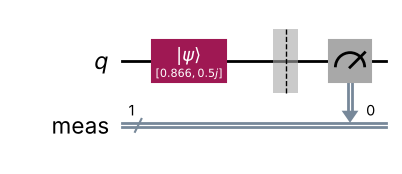

In [5]:
def circuito_que_prepara(estado):
    qc = QuantumCircuit(1)
    qc.initialize(estado.data, 0)   # prepara el qubit en el estado dado
    qc.measure_all()                # mide en la base computacional
    return qc

def frecuencias(estado, shots=SHOTS):
    qc = circuito_que_prepara(estado)
    resultado = sampler.run([qc], shots=shots).result()[0]
    conteos = resultado.data.meas.get_counts()
    return {k: conteos.get(k, 0) / shots for k in ["0", "1"]}, conteos

circuito_que_prepara(psi).draw("mpl")

In [6]:
filas = []
estados_a = {"psi": psi}
estados_a.update({"psi' (" + k + ")": v[0] for k, v in soluciones.items()})
for nombre, estado in estados_a.items():
    exacta = estado.probabilities_dict()
    frec, _ = frecuencias(estado)
    filas.append([nombre, exacta.get("0", 0), frec["0"], exacta.get("1", 0), frec["1"]])

tabla_a = pd.DataFrame(filas, columns=["estado", "P(0) exacta", "frecuencia 0", "P(1) exacta", "frecuencia 1"])
tabla_a.round(4)

,estado,P(0) exacta,frecuencia 0,P(1) exacta,frecuencia 1
0,psi,0.75,0.7555,0.25,0.2445
1,psi' (tau=0),0.75,0.7452,0.25,0.2547
2,psi' (tau=pi/2),0.75,0.7418,0.25,0.2582
3,psi' (tau=-pi/2),0.75,0.7620,0.25,0.2380
4,"psi' (tau=0, eta=1)",0.75,0.7570,0.25,0.2430


Las probabilidades exactas de todas las $|\psi'\rangle$ son las de $|\psi\rangle$ ($0.75$ y $0.25$), y las frecuencias se acercan a ellas; cada frecuencia es una proporción muestral, con desviación estándar $\sqrt{P(1-P)/\text{SHOTS}}=\sqrt{0.75\cdot0.25/4000}\approx0.007$, y las diferencias con la probabilidad exacta son de ese orden.

### La suma normalizada es $|1\rangle$ salvo fase global

Se calcula $|\psi\rangle+e^{i\eta}|\psi'\rangle$, se normaliza, y se compara con $|1\rangle$ usando `equiv`, que dice si dos estados son iguales salvo fase global. También se simulan mediciones del estado normalizado: deberían salir solo unos.

In [7]:
uno = Statevector.from_label("1")
filas = []
for nombre, (psi_p, c, eta) in soluciones.items():
    suma = psi.data + np.exp(1j * eta) * psi_p.data         # |psi> + e^{i eta}|psi'>
    norma = np.linalg.norm(suma)
    normalizado = Statevector(suma / norma)
    frec, _ = frecuencias(normalizado)
    filas.append([nombre, np.round(suma, 4), round(norma, 4), round(abs(c), 4),
                  normalizado.equiv(uno), frec["0"], frec["1"]])

tabla_suma = pd.DataFrame(filas, columns=["solución", "psi + e^{i eta} psi'", "norma", "|c|",
                                          "igual a |1> salvo fase", "frecuencia 0", "frecuencia 1"])
tabla_suma

,solución,psi + e^{i eta} psi',norma,|c|,igual a |1> salvo fase,frecuencia 0,frecuencia 1
0,tau=0,"[0j, 1j]",1.0000,1.0000,True,0.0,1.0
1,tau=pi/2,"[0j, (-0.5+0.5j)]",0.7071,0.7071,True,0.0,1.0
2,tau=-pi/2,"[0j, (0.5+0.5j)]",0.7071,0.7071,True,0.0,1.0
3,"tau=0, eta=1","[-0j, (-0+1j)]",1.0000,1.0000,True,0.0,1.0


En todos los casos la coordenada de $|0\rangle$ de la suma es $0$, la norma de la suma es $|c|$ (porque la suma es $c|1\rangle$), el estado normalizado es $|1\rangle$ salvo fase y en las mediciones simuladas solo sale $1$. Con $\eta=1$ se obtiene la misma suma que con $\eta=0$, porque $\eta$ solo compensa la fase global con la que se escribe $|\psi'\rangle$.

## (b) El estado mixto $p\rho+(1-p)\rho'$

Para cada $p$ se arma la matriz con `DensityMatrix`, que a partir de un `Statevector` calcula el proyector $|\psi\rangle\langle\psi|$. Las probabilidades exactas son la diagonal de la matriz (punto 1.4).

Para simular las mediciones se usa lo que significa el estado mixto: en cada medición el qubit está en $|\psi\rangle$ con probabilidad $p$ y en $|\psi'\rangle$ con probabilidad $1-p$. Entonces, de los `SHOTS` disparos, el número que se hace con $|\psi\rangle$ es una variable binomial con parámetros `SHOTS` y $p$; esos disparos se corren con el circuito de $|\psi\rangle$, los demás con el de $|\psi'\rangle$, y se juntan los conteos.

In [8]:
psi_p, c, _ = soluciones["tau=0"]     # se usa la solución de tau = 0 del punto 1.3
rho = DensityMatrix(psi)
rho_p = DensityMatrix(psi_p)

print("rho =");  print(np.round(rho.data, 4))
print("rho' ="); print(np.round(rho_p.data, 4))

rho =
[[0.75+0.j    0.  -0.433j]
 [0.  +0.433j 0.25+0.j   ]]
rho' =
[[0.75+0.j    0.  +0.433j]
 [0.  -0.433j 0.25+0.j   ]]


In [9]:
def mezcla(p, rho, rho_prima):
    return DensityMatrix(p * rho.data + (1 - p) * rho_prima.data)

def frecuencias_mezcla(p, estado, estado_prima, shots=SHOTS):
    n_psi = rng.binomial(shots, p)          # cuántas veces el qubit está en |psi>
    conteos = {"0": 0, "1": 0}
    for est, n in [(estado, n_psi), (estado_prima, shots - n_psi)]:
        if n > 0:
            _, cts = frecuencias(est, shots=n)
            for k in cts:
                conteos[k] += cts[k]
    return {k: conteos[k] / shots for k in conteos}

valores_p = [0, 0.25, 0.5, 0.75, 1]
filas = []
mezclas = {}
for p in valores_p:
    rho_mix = mezcla(p, rho, rho_p)
    mezclas[p] = rho_mix
    exacta = rho_mix.probabilities_dict()
    frec = frecuencias_mezcla(p, psi, psi_p)
    filas.append([p, exacta.get("0", 0), frec["0"], exacta.get("1", 0), frec["1"]])

tabla_b = pd.DataFrame(filas, columns=["p", "P(0) exacta", "frecuencia 0", "P(1) exacta", "frecuencia 1"])
tabla_b.round(4)

,p,P(0) exacta,frecuencia 0,P(1) exacta,frecuencia 1
0,0.00,0.75,0.7635,0.25,0.2365
1,0.25,0.75,0.7560,0.25,0.2440
2,0.50,0.75,0.7642,0.25,0.2358
3,0.75,0.75,0.7380,0.25,0.2620
4,1.00,0.75,0.7505,0.25,0.2495


In [10]:
print("rho_p para p = 1/4:")
print(np.round(mezclas[0.25].data, 4))

rho_p para p = 1/4:
[[0.75+0.j     0.  +0.2165j]
 [0.  -0.2165j 0.25+0.j    ]]


Para todos los valores de $p$ las probabilidades exactas son $0.75$ y $0.25$, las mismas de $|\psi\rangle$, como se mostró en el punto 1.4, y las frecuencias simuladas se acercan a ellas (con diferencias del orden de la desviación estándar $\approx0.007$). Solo cambian las entradas fuera de la diagonal de la matriz.

## (c) Vectores de Bloch

Se usan las fórmulas del punto 1.4, que leen el punto de la esfera de las entradas de la matriz:
$$r_x=2\,(\text{parte real de }\rho_{10}),\qquad r_y=2\,(\text{parte imaginaria de }\rho_{10}),\qquad r_z=\rho_{00}-\rho_{11}.$$
Sirven igual para estados puros (con $\rho=|\psi\rangle\langle\psi|$) y para estados mixtos.

In [11]:
def vector_bloch(rho):
    m = rho.data if isinstance(rho, DensityMatrix) else DensityMatrix(rho).data
    return np.array([2 * m[1, 0].real, 2 * m[1, 0].imag, (m[0, 0] - m[1, 1]).real])

# Lo que muestra el widget del punto 1.2 para cada estado puro (lectura "r = (...)")
widget = {"psi": (0.000, 0.866, 0.500),
          "psi' (tau=0)": (0.000, -0.866, 0.500),
          "psi' (tau=pi/2)": (0.866, 0.000, 0.500),
          "psi' (tau=-pi/2)": (-0.866, 0.000, 0.500),
          "estado final |1>": (0.000, 0.000, -1.000)}

estados_c = {"psi": psi,
             "psi' (tau=0)": soluciones["tau=0"][0],
             "psi' (tau=pi/2)": soluciones["tau=pi/2"][0],
             "psi' (tau=-pi/2)": soluciones["tau=-pi/2"][0],
             "estado final |1>": uno}
filas = []
for nombre, est in estados_c.items():
    r = vector_bloch(est)
    filas.append([nombre, *np.round(r, 3), widget[nombre], np.allclose(r, widget[nombre], atol=1e-3)])
for p, rho_mix in mezclas.items():
    r = vector_bloch(rho_mix)
    filas.append([f"mezcla p={p}", *np.round(r, 3), "(no está en el widget)", "-"])

tabla_c = pd.DataFrame(filas, columns=["estado", "r_x", "r_y", "r_z", "widget", "coinciden"])
tabla_c

,estado,r_x,r_y,r_z,widget,coinciden
0,psi,0.000,0.866,0.5,"(0.0, 0.866, 0.5)",True
1,psi' (tau=0),0.000,-0.866,0.5,"(0.0, -0.866, 0.5)",True
2,psi' (tau=pi/2),0.866,-0.000,0.5,"(0.866, 0.0, 0.5)",True
3,psi' (tau=-pi/2),-0.866,-0.000,0.5,"(-0.866, 0.0, 0.5)",True
4,estado final |1>,0.000,0.000,-1.0,"(0.0, 0.0, -1.0)",True
5,mezcla p=0,0.000,-0.866,0.5,(no está en el widget),-
6,mezcla p=0.25,0.000,-0.433,0.5,(no está en el widget),-
7,mezcla p=0.5,0.000,0.000,0.5,(no está en el widget),-
8,mezcla p=0.75,0.000,0.433,0.5,(no está en el widget),-
9,mezcla p=1,0.000,0.866,0.5,(no está en el widget),-


Los vectores de los estados puros coinciden con los que muestra el widget (con 3 decimales, que es lo que muestra la lectura del widget). Todos los estados, puros y mixtos, salvo el estado final, tienen $r_z=0.5$: están a la misma altura, en el paralelo de $|\psi\rangle$ o en una cuerda de ese paralelo. Los estados puros tienen $|\vec r|=1$ y las mezclas con $0<p<1$ tienen $|\vec r|<1$:

In [12]:
for nombre, est in estados_c.items():
    print(f"{nombre:18s} |r| = {np.linalg.norm(vector_bloch(est)):.4f}")
for p, rho_mix in mezclas.items():
    print(f"mezcla p={p:<9} |r| = {np.linalg.norm(vector_bloch(rho_mix)):.4f}")

psi                |r| = 1.0000
psi' (tau=0)       |r| = 1.0000
psi' (tau=pi/2)    |r| = 1.0000
psi' (tau=-pi/2)   |r| = 1.0000
estado final |1>   |r| = 1.0000
mezcla p=0         |r| = 1.0000
mezcla p=0.25      |r| = 0.6614
mezcla p=0.5       |r| = 0.5000
mezcla p=0.75      |r| = 0.6614
mezcla p=1         |r| = 1.0000


Gráfica con `plot_bloch_vector` para $|\psi\rangle$ y una solución, y una gráfica con todos los puntos juntos (la clase `Bloch` permite poner varios puntos en la misma esfera).

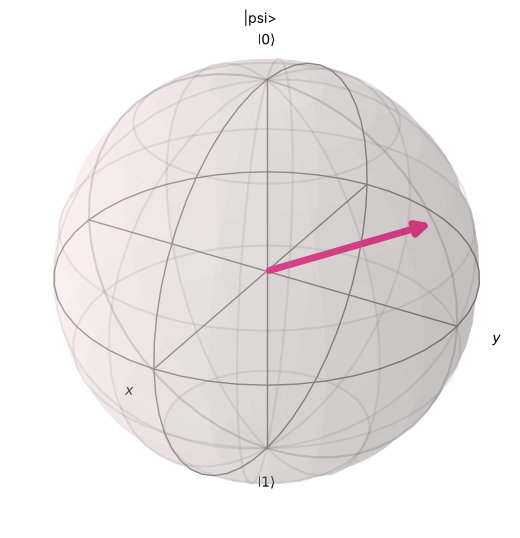

In [13]:
fig1 = plot_bloch_vector(vector_bloch(psi), title="|psi>")
fig1

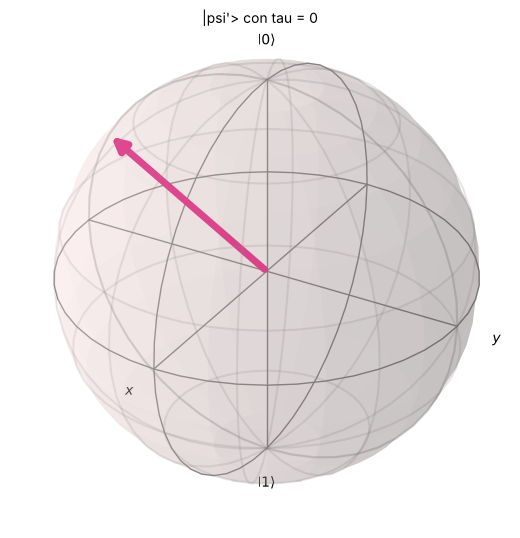

In [14]:
fig2 = plot_bloch_vector(vector_bloch(soluciones["tau=0"][0]), title="|psi'> con tau = 0")
fig2

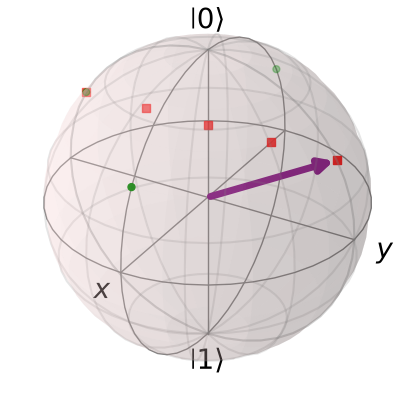

In [15]:
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(projection="3d")
b = Bloch(axes=ax)
b.add_vectors(vector_bloch(psi))
# las tres soluciones (puntos verdes)
pts = np.array([vector_bloch(estados_c[k]) for k in ["psi' (tau=0)", "psi' (tau=pi/2)", "psi' (tau=-pi/2)"]])
b.add_points(pts.T)
# las mezclas con la solución de tau = 0 (puntos rojos)
pts_mix = np.array([vector_bloch(mezclas[p]) for p in valores_p])
b.add_points(pts_mix.T)
b.point_color = ["g", "r"]
b.vector_color = ["purple"]
b.render()   # morado: psi, verde: soluciones del 1.3, rojo: mezclas del 1.4
fig.savefig("bloch_todos.png", dpi=200, bbox_inches="tight")
plt.show()

## Prueba con estados al azar

Para ver que todo funciona para un $|\psi\rangle$ cualquiera, se repiten las comprobaciones con estados al azar y valores de $\tau$, $\eta$ y $p$ al azar.

In [16]:
def estado_al_azar():
    v = rng.normal(size=2) + 1j * rng.normal(size=2)
    return v / np.linalg.norm(v)

todo_bien = True
for _ in range(200):
    a, b_ = estado_al_azar()
    tau = rng.uniform(-np.pi + 0.01, np.pi - 0.01)
    eta = rng.uniform(-np.pi, np.pi)
    p = rng.uniform(0, 1)
    estado = Statevector([a, b_])
    estado_p, c = construir_psi_prima(a, b_, tau, eta)
    suma = estado.data + np.exp(1j * eta) * estado_p.data
    rho_mix = mezcla(p, DensityMatrix(estado), DensityMatrix(estado_p))
    r1, r2, rm = vector_bloch(estado), vector_bloch(estado_p), vector_bloch(rho_mix)
    pruebas = [np.allclose(estado.probabilities(), estado_p.probabilities()),   # mismas probabilidades
               abs(suma[0]) < 1e-12,                                          # se cancela |0>
               np.isclose(suma[1], c),                                        # queda c|1>
               Statevector(suma / np.linalg.norm(suma)).equiv(uno),           # |1> salvo fase
               np.allclose(rho_mix.probabilities(), estado.probabilities()),   # 1.4
               np.allclose(rm, p * r1 + (1 - p) * r2),                         # punto de la cuerda
               np.isclose(r1[2], r2[2])]                                      # misma altura
    todo_bien = todo_bien and all(pruebas)

print("Todas las pruebas se cumplen:", todo_bien)

Todas las pruebas se cumplen: True


In [17]:
# Caso sin solución: |psi> = |0>
try:
    construir_psi_prima(1, 0, 0.0)
except ValueError as e:
    print("Error esperado:", e)

Error esperado: beta = 0: |psi> es |0> y no existe |psi'>
